# Лабораторна робота №1

## Тема роботи

Дослідження ефективності послідовної та паралельної обробки даних у Python.

## Мета роботи

Навчитися розподіляти незалежні CPU-обчислення між процесами та оцінювати прискорення з урахуванням накладних витрат.

## Завдання

Варіант **3**: N=500 000, x∈[1; 30 000], K=200, seed=42. Для кожного елемента обчислити

$$f(x)=\sum_{i=1}^{200}\sqrt{x+i}\sin(x+i).$$

Усі значення обчислюються без кешування повторюваних x та без заміни циклу векторною операцією. Отже, кожна реалізація виконує 100 мільйонів доданків на один повний прохід.

## Теоретичні відомості

Процеси мають окремі інтерпретатори Python, тому можуть виконувати цей цикл одночасно. Ціна такого підходу — запуск інтерпретаторів, серіалізація даних та результатів, планування і синхронізація.

$$S_p=T_{seq}/T_p,\qquad E_p=S_p/p\cdot100\%.$$

У таблиці окремо подано справжній послідовний алгоритм і ProcessPoolExecutor з одним процесом. Прискорення останнього не прирівнюється до одиниці штучно.



## Використані технології та підготовка середовища

Python, pandas, NumPy, Matplotlib та засоби паралельності з модуля роботи. Встановлення: `python -m pip install -r requirements.txt`. Повні обчислення: `python -m lab01.main`. Notebook відтворює аналіз збереженого повного експерименту; worker-функції розміщені в імпортованих `.py`, а запуск пулів відбувається через CLI.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import random
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

root = Path.cwd().resolve()
if not (root / "common").exists():
    root = root.parent
if not (root / "common").exists():
    raise RuntimeError("Відкрийте notebook у корені проєкту або каталозі лабораторної.")
sys.path.insert(0, str(root))
from lab01 import algorithms as a

result_dir = root / "lab01" / "results"


def read_json(name):
    return json.loads((result_dir / name).read_text(encoding="utf-8"))


meta = read_json("metadata.json")
timings = pd.read_csv(result_dir / "timings.csv")
raw = pd.read_csv(result_dir / "timings_raw.csv")
pd.set_option("display.max_columns", 16)
assert not meta.get("quick", False), "Для захисту потрібен повний запуск."

## 1. Генерація даних

Варіант №3 і відтворюваність генератора.

In [2]:
display(meta)
rng = random.Random(42)
display([rng.randint(1, 30_000) for _ in range(10)])

{'environment': {'python': '3.12.6',
  'os': 'Windows-11-10.0.26200-SP0',
  'logical_cpus': 16,
  'libraries': {'numpy': '2.1.3',
   'pandas': '2.2.3',
   'matplotlib': '3.9.2',
   'pyspark': '4.0.3',
   'nbformat': '5.11.1',
   'pytest': '9.0.3'}},
 'variant': 3,
 'n': 500000,
 'k': 200,
 'seed': 42,
 'range': [1, 30000],
 'quick': False,
 'generation_seconds': 0.210382600002049,
 'workers': [1, 2, 4, 8],
 'oversubscribed': [],
 'timing_scope': 'Розбиття + spawn + передавання + обчислення + збирання + закриття пулу'}

[20953, 3649, 820, 24300, 9013, 8025, 7315, 4573, 24133, 3359]

## 2. Послідовний алгоритм

Формула реалізована в імпортованому модулі; малий контрольний набір.

In [3]:
print(inspect.getsource(a.process_value))
display(pd.read_csv(result_dir / "function_check.csv"))

def process_value(x: int, k: int) -> float:
    if k < 1 or x < 0:
        raise ValueError("Потрібні x >= 0 та k >= 1.")
    result = 0.0
    for i in range(1, k + 1):
        result += math.sqrt(x + i) * math.sin(x + i)
    return result



,x,f(x)
0,10,13.647821
1,20,-13.344163
2,30,9.817288
3,40,-3.544196
4,50,-3.999995


## 3. Час послідовної обробки

Повні вимірювання без вартості запису результатів.

In [4]:
display(raw[raw.method == "sequential"])

,workload,method,workers,effective_workers,repeat,seconds,verified
0,cpu,sequential,1,1,1,16.072087,True
5,cpu,sequential,1,1,2,15.138256,True
10,cpu,sequential,1,1,3,15.837734,True


## 4. Розподіл даних

Демонстрація п'яти частин та коректного нерівного розбиття.

In [5]:
display(read_json("split_demo.json"))
display(a.split_data(list(range(13)), 5))

{'parts': 5, 'sizes': [100000, 100000, 100000, 100000, 100000]}

[[0, 1, 2], [3, 4, 5], [6, 7, 8], [9, 10], [11, 12]]

## 5. ProcessPoolExecutor

Пул запускають з CLI, що безпечно для Windows. Тут відображається фактична реалізація.

In [6]:
print(inspect.getsource(a.parallel_processing))

def parallel_processing(data: list[int], k: int, workers: int) -> list[float]:
    if workers < 1:
        raise ValueError("Кількість процесів має бути додатною.")
    # Чотири задачі на процес зменшують дисбаланс; порядок map збережено.
    chunks = split_data(data, min(len(data) or 1, workers * 4))
    with ProcessPoolExecutor(
        max_workers=workers, mp_context=mp.get_context("spawn")
    ) as pool:
        results = pool.map(process_chunk, [(chunk, k) for chunk in chunks])
        return [value for chunk in results for value in chunk]



## 6. Кількість процесів

Окремі вимірювання p=1,2,4,8, включно з усіма накладними витратами.

In [7]:
display(raw[raw.method == "process_pool"])

,workload,method,workers,effective_workers,repeat,seconds,verified
1,cpu,process_pool,1,1,1,20.548669,True
2,cpu,process_pool,2,2,1,10.785412,True
3,cpu,process_pool,4,4,1,6.994333,True
4,cpu,process_pool,8,8,1,5.076619,True
6,cpu,process_pool,1,1,2,15.740582,True
7,cpu,process_pool,2,2,2,12.845067,True
8,cpu,process_pool,4,4,2,6.372257,True
9,cpu,process_pool,8,8,2,4.916334,True
11,cpu,process_pool,1,1,3,16.212795,True
12,cpu,process_pool,2,2,3,10.949289,True


## 7. Speedup та Efficiency

Медіанні значення; baseline є окремим послідовним алгоритмом.

In [8]:
display(timings)
assert np.allclose(timings.efficiency_pct, timings.speedup / timings.workers * 100)

,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,cpu,sequential,1,1,15.837734,15.138256,16.072087,True,3,1.000000,100.000000
1,cpu,process_pool,1,1,16.212795,15.740582,20.548669,True,3,0.976866,97.686639
2,cpu,process_pool,2,2,10.949289,10.785412,12.845067,True,3,1.446462,72.323119
3,cpu,process_pool,4,4,6.994333,6.372257,7.433831,True,3,2.264367,56.609168
4,cpu,process_pool,8,8,5.076619,4.916334,5.676624,True,3,3.119741,38.996757


## 8. Правильність

У CLI перевірено кожен елемент кожного запуску; notebook додатково перевіряє перші десять.

In [9]:
values = np.load(result_dir / "values.npy")
assert len(values) == meta["n"]
rng = random.Random(meta["seed"])
sample = [rng.randint(1, 30_000) for _ in range(10)]
a.assert_equivalent(values[:10].tolist(), a.sequential_processing(sample, meta["k"]))
display({"elements": len(values), "all_runs_verified": bool(raw.verified.all())})

{'elements': 500000, 'all_runs_verified': True}

## 9. Графіки

Час, прискорення та ефективність з однакових вимірювань.

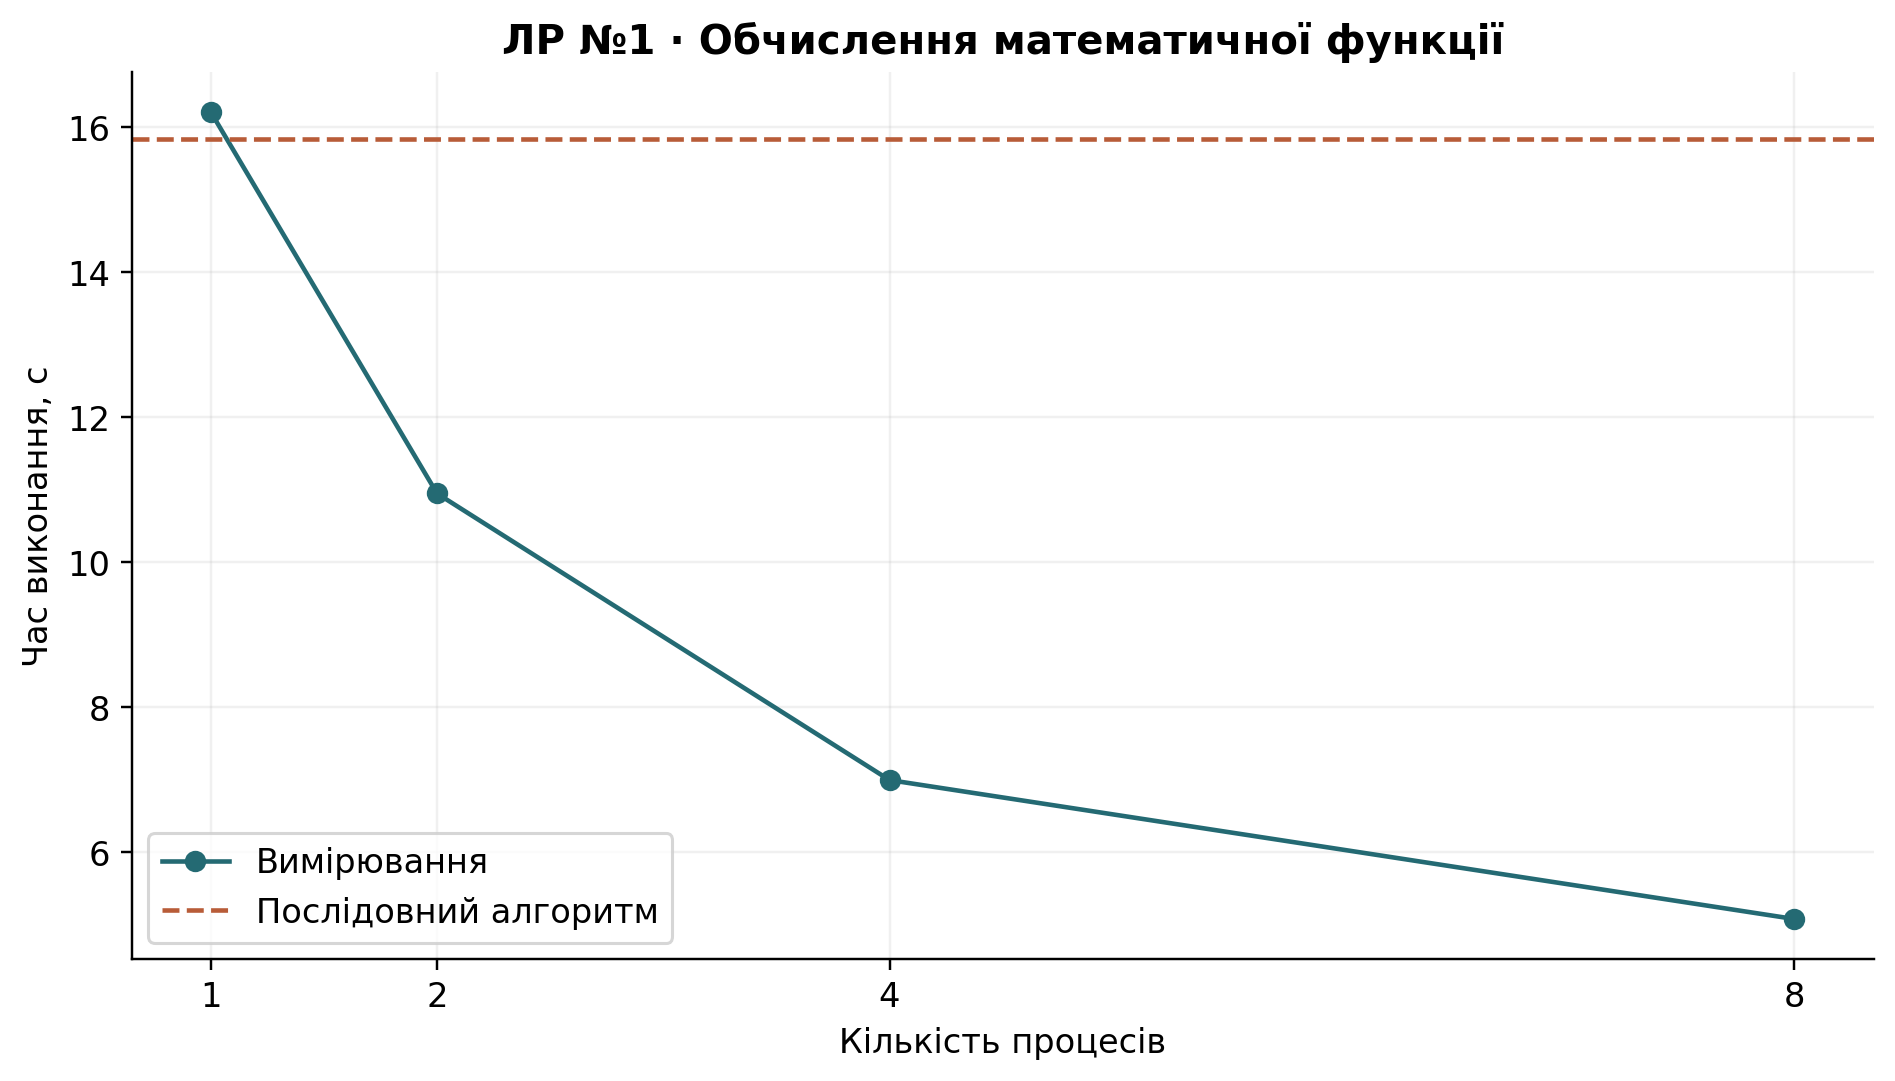

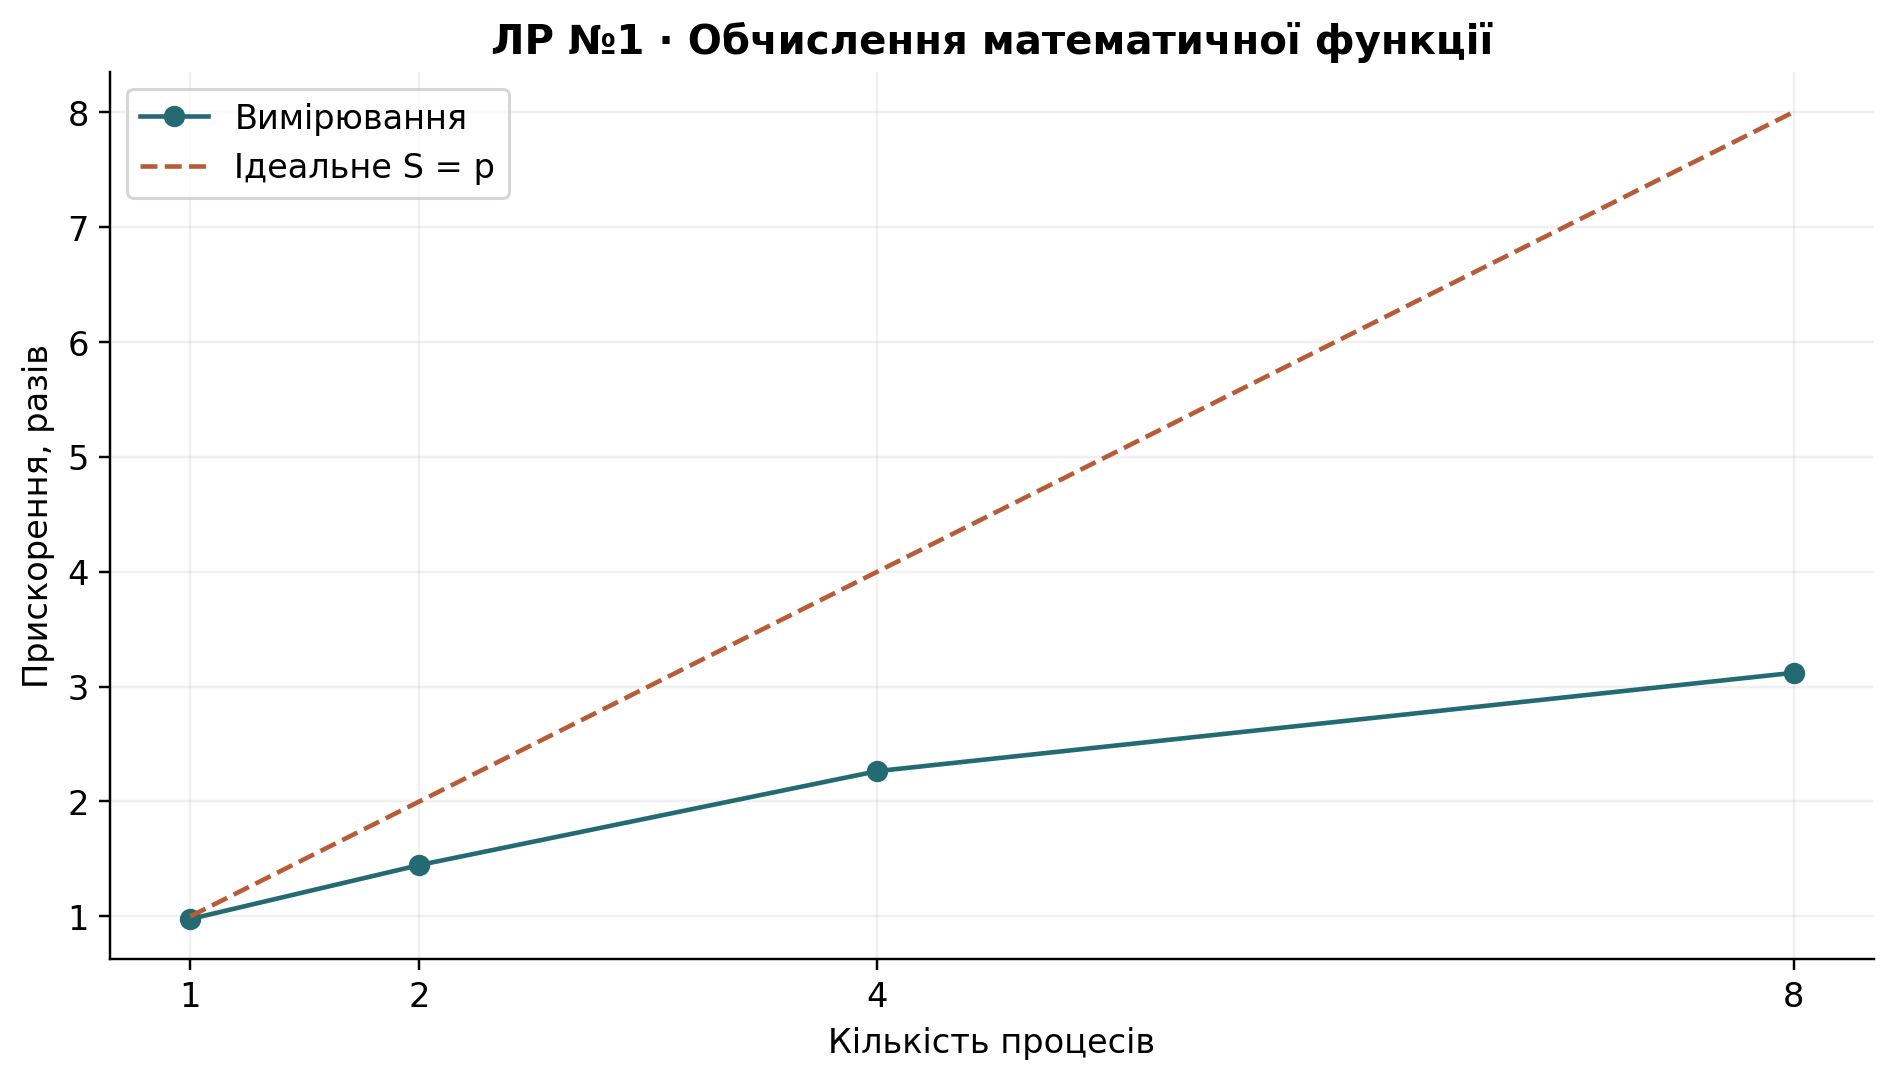

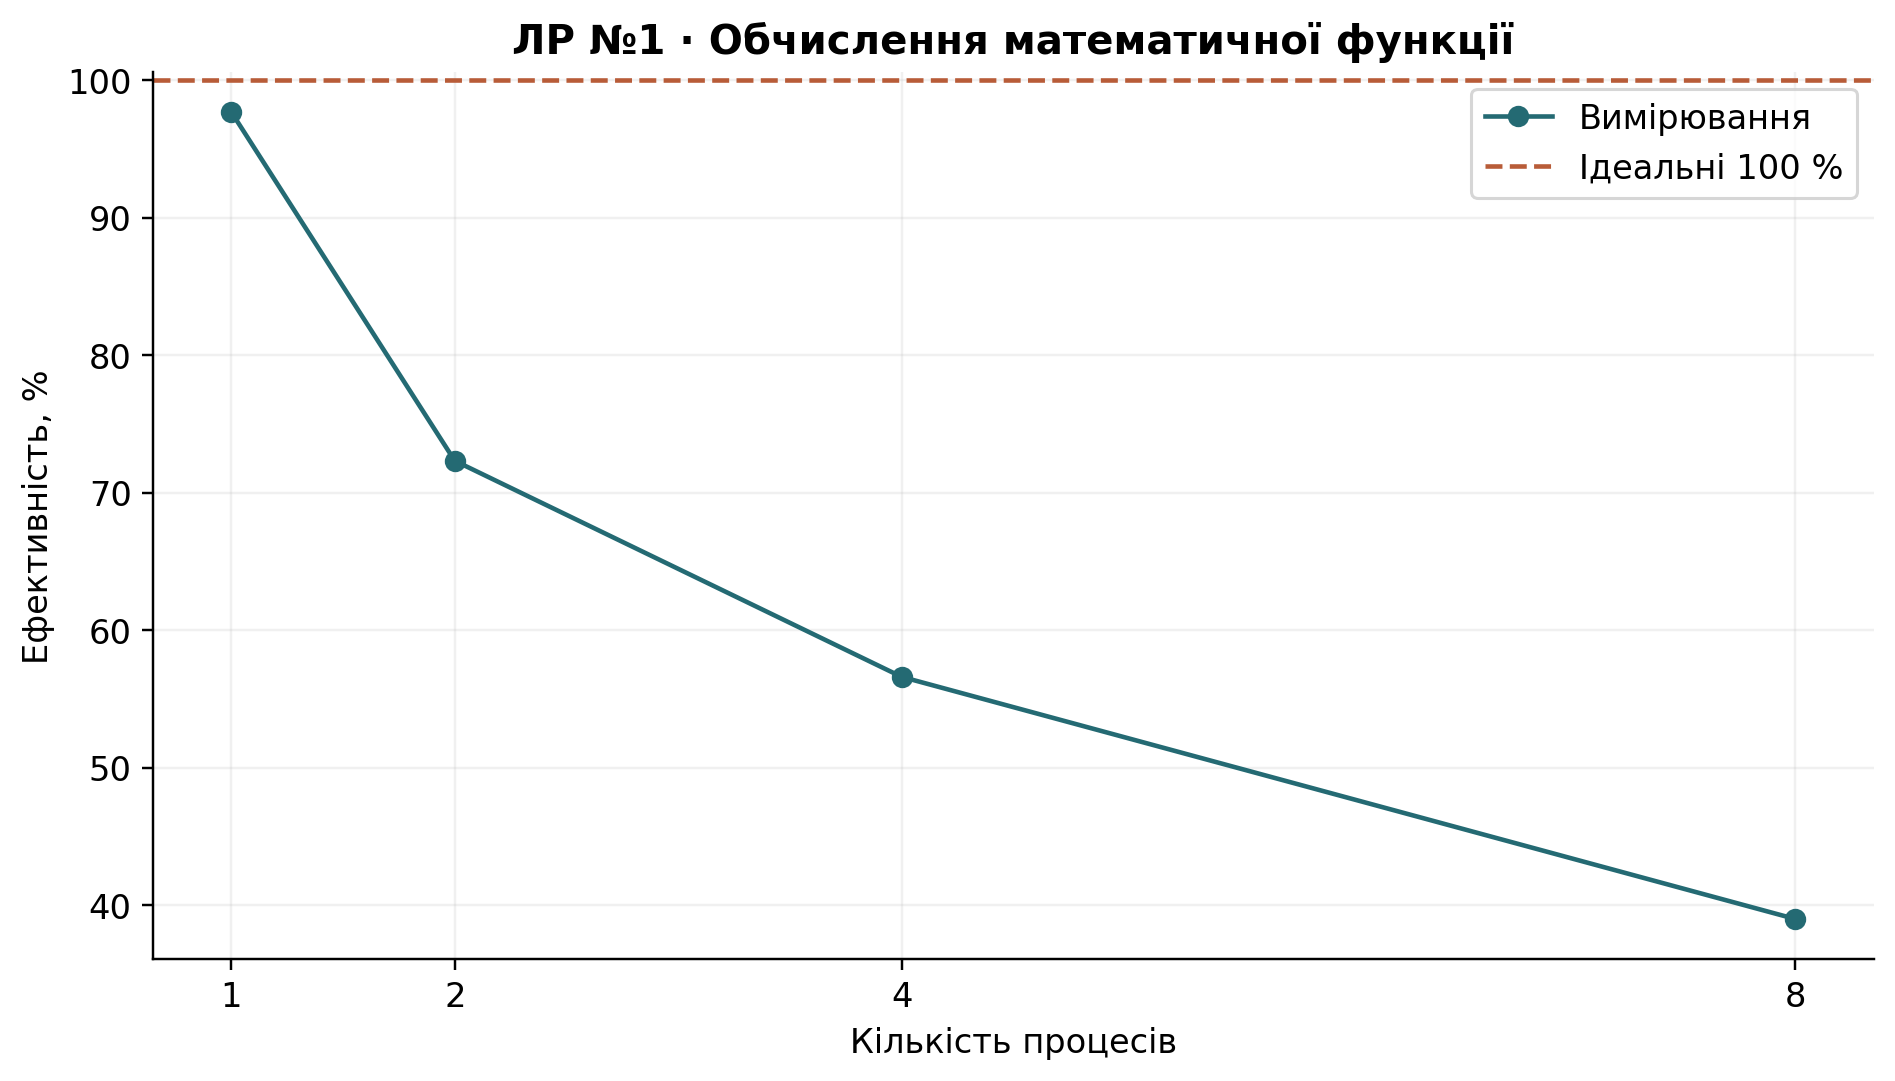

In [10]:
for name in ["time", "speedup", "efficiency"]:
    display(Image(filename=str(result_dir / f"{name}.png")))

## Аналіз результатів

Повний варіант №3; три повтори всіх п'яти конфігурацій. Кожен результат перевірений.

Послідовний прохід має медіану 15.8377 с. Пул з одним процесом — 16.2128 с (S=0.977), що демонструє вартість організації пулу. Найшвидший досліджений пул: p=8, 5.0766 с, S=3.120, E=39.00%. Навіть за наявності 16 логічних CPU ідеальне прискорення не гарантоване: ядра ділять ресурси, а кожен запуск передає великий масив через IPC. Розкид мінімум–максимум відображає нестабільність середовища; три повтори не є повноцінним статистичним дослідженням. Оптимум стосується цього комп'ютера, реалізації та поточного навантаження. Для цього обсягу найкращий пул прискорив обчислення.

In [11]:
display(timings)

,workload,method,workers,effective_workers,seconds,min_seconds,max_seconds,verified,repeats,speedup,efficiency_pct
0,cpu,sequential,1,1,15.837734,15.138256,16.072087,True,3,1.000000,100.000000
1,cpu,process_pool,1,1,16.212795,15.740582,20.548669,True,3,0.976866,97.686639
2,cpu,process_pool,2,2,10.949289,10.785412,12.845067,True,3,1.446462,72.323119
3,cpu,process_pool,4,4,6.994333,6.372257,7.433831,True,3,2.264367,56.609168
4,cpu,process_pool,8,8,5.076619,4.916334,5.676624,True,3,3.119741,38.996757


## Висновки

Найменший час має process_pool, p=8: 5.0766 с. Правильність усіх повних запусків підтверджено; доцільність паралельності визначається співвідношенням обчислень і накладних витрат.

## Контрольні питання

1. **Що таке паралельна обробка даних?** Виконання незалежних частин обчислень одночасно на кількох обчислювальних ресурсах; конкурентність також допускає перекриття очікувань без одночасного CPU-виконання.
2. **Чим послідовна обробка відрізняється від паралельної?** У першій наступна частина починається після попередньої; у другій частини можуть виконуватися одночасно, після чого результати об'єднуються.
3. **Які задачі доцільно виконувати паралельно?** Великі незалежні CPU-обчислення з невеликими витратами на обмін або незалежні I/O-операції з тривалим очікуванням.
4. **Що таке CPU-bound задача?** Задача, час якої переважно визначає виконання обчислень процесором, як цикл з sqrt та sin у цій роботі.
5. **Що таке процес?** Екземпляр програми з власним адресним простором, ресурсами та щонайменше одним потоком виконання.
6. **Чим процес відрізняється від потоку?** Процеси ізолюють пам'ять, а потоки одного процесу спільно використовують її. Для потоків потрібна обережна синхронізація спільних змінюваних об'єктів.
7. **Для чого використовується ProcessPoolExecutor?** Для запуску функцій у пулі процесів через futures або map з керованим життєвим циклом і передаванням винятків.
8. **Що таке пул процесів?** Набір робочих процесів, які отримують задачі з черги та можуть виконувати кілька задач протягом свого існування.
9. **Навіщо розділяти набір даних на частини?** Щоб створити незалежні задачі, збалансувати навантаження та уникнути надмірних витрат на передавання кожного окремого елемента.
10. **Що таке Speedup?** Відношення часу послідовного алгоритму до часу досліджуваного способу. Значення менше 1 означає уповільнення.
11. **Як розраховується Speedup?** S_p=T_seq/T_p для однакових вхідних даних та меж вимірювання.
12. **Що таке Efficiency?** Частка ідеального прискорення, досягнута в середньому на одного виконавця.
13. **Як розраховується Efficiency?** E_p=S_p/p, або E_p=S_p/p×100% у відсотках.
14. **Чому реальне прискорення зазвичай менше за теоретичне?** Через послідовні ділянки, запуск, обмін, дисбаланс, конкуренцію за пам'ять і обмежені фізичні ядра. Закон Амдала задає межу 1/(s+(1-s)/p).
15. **Чому збільшення кількості процесів не завжди приводить до прискорення?** Після насичення CPU додаткові процеси збільшують перемикання контексту та обмін; кількість незалежних задач також обмежує корисний паралелізм.
16. **Що таке накладні витрати паралельного виконання?** Робота, потрібна для організації виконання: створення процесів, pickle, IPC, планування, синхронізація та збирання результатів.
17. **Який зв'язок між кількістю процесів і кількістю ядер CPU?** Для CPU-bound задач корисне p обмежене доступними ядрами. Логічні CPU не рівнозначні фізичним ядрам; оптимум встановлюють вимірюванням.
18. **Чому необхідно перевіряти однаковість результатів послідовного та паралельного алгоритмів?** Прискорення має сенс лише для еквівалентних обчислень. Перевірка виявляє втрати, дублювання, перестановки та помилки об'єднання.
19. **У яких випадках паралельна обробка може бути недоцільною?** Для малих задач, великих обсягів обміну, сильних залежностей, недостатньої пам'яті та ситуацій, де накладні витрати перевищують економію часу.
